In [ ]:
import pandas as pd
import numpy as np
from pathlib import Path
import joblib

import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

PROJECT_ROOT = Path.cwd().parent
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
MODELS_DIR = PROJECT_ROOT / "models"

model_bundle = joblib.load(
    MODELS_DIR / "SentinelAi_model.joblib"
)

anomaly_pipeline = model_bundle["anomaly_pipeline"]
attack_pipeline = model_bundle["attack_pipeline"]
FEATURES = model_bundle['features']

test_df = pd.read_parquet(PROCESSED_DIR / "test.parquet")

In [4]:
X_test = test_df[FEATURES]

y_train_binary = test_df['Bin Label']
if_pred = anomaly_pipeline.predict(X_test)


y_pred_binary = np.where(if_pred == -1, 1, 0)

print("ISOLATION FOREST RESULTS\n")
print(f"Accuracy Score: {accuracy_score(y_train_binary, y_pred_binary)}")
print(f"Precision Score: {precision_score(y_train_binary, y_pred_binary, zero_division=0)}")
print(f"Recall Score: {recall_score(y_train_binary, y_pred_binary, zero_division=0)}")
print(f"F1 Score: {f1_score(y_train_binary, y_pred_binary, zero_division=0)}\n")
print(f"Classification Report: {classification_report(
    y_train_binary, 
    y_pred_binary,
    target_names=['BENIGN', 'ATTACK'],
    zero_division=0
    )}")

ISOLATION FOREST RESULTS

Accuracy Score: 0.8207086155414755
Precision Score: 0.5858211152328799
Recall Score: 0.6534968881882522
F1 Score: 0.6178112071039905

Classification Report:               precision    recall  f1-score   support

      BENIGN       0.90      0.87      0.88    213723
      ATTACK       0.59      0.65      0.62     60897

    accuracy                           0.82    274620
   macro avg       0.74      0.76      0.75    274620
weighted avg       0.83      0.82      0.82    274620



In [5]:
attack_test = test_df[
    test_df["Bin Label"] == 1
]

X_test_attack = attack_test[FEATURES]
y_test_attack = attack_test["Attack Type"]

rf_predictions = attack_pipeline.predict(
    X_test_attack
)

print("Random Forest Results\n")

print(
    classification_report(
        y_test_attack,
        rf_predictions,
        zero_division=0
    )
)

Random Forest Results

              precision    recall  f1-score   support

           1       1.00      1.00      1.00       111
           2       1.00      1.00      1.00     14271
           3       1.00      1.00      1.00      1135
           4       1.00      1.00      1.00     23770
           5       0.97      1.00      0.98       260
           6       1.00      1.00      1.00       518
           7       1.00      1.00      1.00       596
           8       1.00      0.71      0.83         7
           9       1.00      1.00      1.00     19770
          10       1.00      1.00      1.00       444
          11       0.93      0.93      0.93        15

    accuracy                           1.00     60897
   macro avg       0.99      0.97      0.98     60897
weighted avg       1.00      1.00      1.00     60897



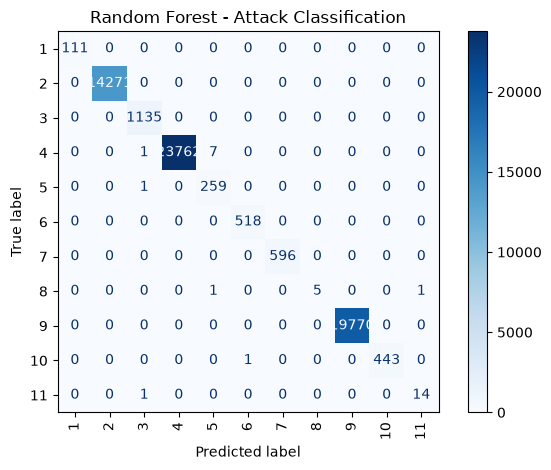

In [9]:
cm = confusion_matrix(
    y_test_attack,
    rf_predictions,
    labels=attack_pipeline.classes_
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=attack_pipeline.classes_
)

disp.plot(
    cmap="Blues",
    xticks_rotation=90,
    values_format="d"
)

plt.title("Random Forest - Attack Classification")
plt.tight_layout()
plt.show()